In [1]:
import scanpy as sc
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import warnings
import os

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option('display.max_columns', 100)

sc.settings.figdir = "figures_draft"
sc.settings.set_figure_params(dpi=60, dpi_save=300,vector_friendly=True )
import matplotlib as mpl
mpl.rcParams['pdf.fonttype'] = 42
mpl.rcParams['ps.fonttype']  = 42
mpl.rcParams['svg.fonttype'] = 'none'
mpl.rcParams['font.family']  = 'DejaVu Sans'

!pwd

/lustre/scratch126/cellgen/lotfollahi/so21/neuroID/paper_figures


In [2]:
import pertpy as pt

/software/cellgen/team233/so21/envs/scanpy/lib/python3.12/site-packages/jaxlib/plugin_support.py:71: RuntimeWarning: JAX plugin jax_cuda12_plugin version 0.5.3 is installed, but it is not compatible with the installed jaxlib version 0.8.2, so it will not be used.
  warnings.warn(
/software/cellgen/team233/so21/envs/scanpy/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
ERROR:2026-10-09 09:40:39,217:jax._src.xla_bridge:475: Jax plugin configuration error: Exception when calling jax_plugins.xla_cuda12.initialize()
Traceback (most recent call last):
  File "/software/cellgen/team233/so21/envs/scanpy/lib/python3.12/site-packages/jax/_src/xla_bridge.py", line 473, in discover_pjrt_plugins
    plugin_module.initialize()
  File "/software/cellgen/team233/so21/envs/scanpy/lib/python3.12/site-packages/jax_plugin

In [3]:
figsave='figures_draft'

In [4]:
from scipy import stats
import seaborn as sns
sns.set_style('ticks')

### iNeurons

In [9]:
def run_milo(adata_input,
             pert: str,
             pert_colname='target_gene',
             ctrl='INT',
             rep_colname='sequencing_batch',
             use_rep="CellDISECT_Z_not_sequencing_batch"):
    
    # filter adata
    print (adata_input.X.shape)
    temp_adata = adata_input[adata_input.obs[pert_colname].isin([ctrl,pert])].copy()
    print (temp_adata.X.shape)
    temp_adata.obs[pert_colname] = temp_adata.obs[pert_colname].astype("category").cat.remove_unused_categories()
    print(temp_adata.obs[pert_colname].cat.categories)
    temp_adata.obs[rep_colname]  = temp_adata.obs[rep_colname].astype("category")
    temp_adata.obs["sample_rep_pert"] = (
        temp_adata.obs[rep_colname].astype(str) + "_" + temp_adata.obs[pert_colname].astype(str)
    )
    
    # Initialize object for Milo analysis
    milo = pt.tl.Milo()
    mdata = milo.load(temp_adata)
    print (mdata["rna"].X.shape)
    
    # knn graph
    n_n = int(temp_adata.n_obs/300)
    print (n_n)
    sc.pp.neighbors(mdata["rna"], use_rep=use_rep, n_neighbors=n_n)
    
    # assign cells to a set of representative neighbourhoods on the KNN graph.
    milo.make_nhoods(mdata["rna"], prop=0.1)
    #print (mdata["rna"].obsm["nhoods"])
    
    # visualize the distribution of neighbourhood sizes, 
    # to check that the minimal value of k makes sense, and that the distribution of sizes is not too wide
    nhood_size = np.array(mdata["rna"].obsm["nhoods"].sum(0)).ravel()
    plt.hist(nhood_size, bins=100)
    plt.xlabel("# cells in nhood")
    plt.ylabel("# nhoods")
    plt.show()
    
    # count cells in nhoods for each sample
    mdata = milo.count_nhoods(mdata, sample_col='sample_rep_pert')
    
    # Reorder categories (by default, the last category is taken as the condition of interest)
    mdata["rna"].obs[pert_colname] = mdata["rna"].obs[pert_colname].cat.reorder_categories([ctrl, pert])
    # run
    milo.da_nhoods(mdata,
                   design=f"~{rep_colname}+{pert_colname}",
                   #design=f"~{pert_colname}",
                   model_contrasts=(pert_colname, pert, ctrl),
                   solver="pydeseq2")
    
    old_figsize = plt.rcParams["figure.figsize"]
    plt.rcParams["figure.figsize"] = [10, 5]
    plt.subplot(1, 2, 1)
    plt.hist(mdata["milo"].var.SpatialFDR, bins=50)
    plt.xlabel("SpatialFDR")
    plt.subplot(1, 2, 2)
    plt.plot(mdata["milo"].var.logFC, -np.log10(mdata["milo"].var.SpatialFDR), ".")
    plt.xlabel("log-Fold Change")
    plt.ylabel("- log10(Spatial FDR)")
    plt.title(pert)
    plt.tight_layout()
    plt.show()
    
    milo.build_nhood_graph(mdata)

    plt.rcParams["figure.figsize"] = [7, 7]
    milo.plot_nhood_graph(
        mdata,
        alpha=0.1,  # SpatialFDR level (1%)
        min_size=1,  # Size of smallest dot
        save=f'_milo_{pert}.pdf'
    )
    
    plt.rcParams["figure.figsize"] = old_figsize
    
    
    return mdata


In [6]:
cd_iN = sc.read('../cellDisect/iNeurons_cellDisect_v3_2.h5ad')
cd_iN

AnnData object with n_obs × n_vars = 204719 × 36601
    obs: 'Sample', 'Replicate', 'num_features', 'feature_call', 'num_umis', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'pct_counts_ribo', 'total_counts_hb', 'pct_counts_hb', 'guide_calls', 'target_vector', 'target_gene', 'perturbation', '_cluster', '_scvi_batch', '_scvi_labels', '_scvi_cluster'
    var: 'gene_ids', 'feature_types', 'genome', 'pattern', 'read', 'sequence', 'target_gene_id', 'target_gene_name', 'mt', 'ribo', 'hb', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts'
    uns: 'CellDISECT_Z_0_neighbors', 'CellDISECT_Z_Replicate_neighbors', 'CellDISECT_Z_not_Replicate_neighbors', 'CellDISECT_Z_perturbation_neighbors', 'Replicate_colors', '_cluster', '_scvi_manager_uuid', '_scvi_uuid', 'log1p', 'neighbors', 'pca'
    obsm: 'CellDISECT_Z_0', 'CellDISECT_Z_0_umap', 'CellDISECT_Z_Replicate', 'CellDISECT_Z_Replicate_umap', 'CellDISECT_Z_not_Replicate', 'C

In [7]:
cd_iN.obsm['X_umap'] = cd_iN.obsm['CellDISECT_Z_not_Replicate_umap']

(204719, 36601)
(6853, 36601)
Index(['C2orf49', 'INT'], dtype='object')
(6853, 36601)
22


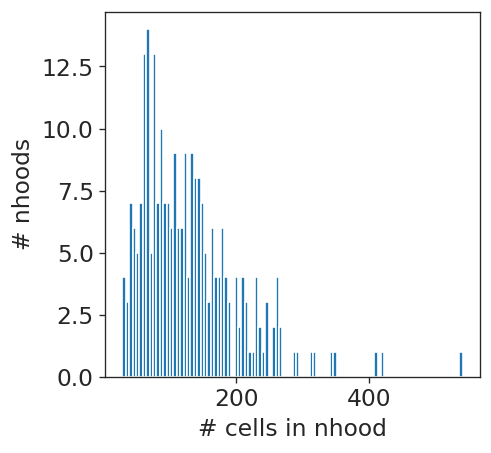

Fitting size factors...
... done in 0.00 seconds.



Using None as control genes, passed at DeseqDataSet initialization


Fitting dispersions...
... done in 0.26 seconds.

Fitting dispersion trend curve...
/software/cellgen/team233/so21/envs/scanpy/lib/python3.12/site-packages/pydeseq2/dds.py:807: UserWarning: The dispersion trend curve fitting did not converge. Switching to a mean-based dispersion trend.
  self._fit_parametric_dispersion_trend(vst)
... done in 0.02 seconds.

/software/cellgen/team233/so21/envs/scanpy/lib/python3.12/site-packages/pydeseq2/dds.py:541: UserWarning: As the residual degrees of freedom is less than 3, the distribution of log dispersions is especially asymmetric and likely to be poorly estimated by the MAD.
  self.fit_dispersion_prior()
Fitting MAP dispersions...
... done in 0.35 seconds.

Fitting LFCs...
... done in 0.32 seconds.

Calculating cook's distance...
... done in 0.01 seconds.

Replacing 0 outlier genes.

Running Wald tests...
... done in 0.24 seconds.



Log2 fold change & Wald test p-value: perturbation C2orf49 vs INT
      baseMean  log2FoldChange     lfcSE      stat        pvalue          padj
0     5.650967       -1.588959  0.934591 -1.700165  8.909986e-02  1.358408e-01
1     5.879619       -1.548102  0.946218 -1.636095  1.018198e-01  1.479569e-01
2     8.825741       -3.761632  1.328284 -2.831948  4.626541e-03  2.264570e-02
3     8.523031        0.546698  0.696126  0.785343  4.322523e-01  4.790635e-01
4    47.057447       11.002556  1.710588  6.432030  1.259109e-10  8.364079e-10
..         ...             ...       ...       ...           ...           ...
252   2.131465       -2.237381  1.568918 -1.426066  1.538492e-01           NaN
253   5.146926       -0.820309  0.838035 -0.978849  3.276548e-01           NaN
254   5.337216       -2.827428  1.352146 -2.091067  3.652208e-02           NaN
255   2.004233       -2.084311  1.668656 -1.249095  2.116302e-01           NaN
256  13.888501       -2.136758  0.900589 -2.372623  1.766230e-02 

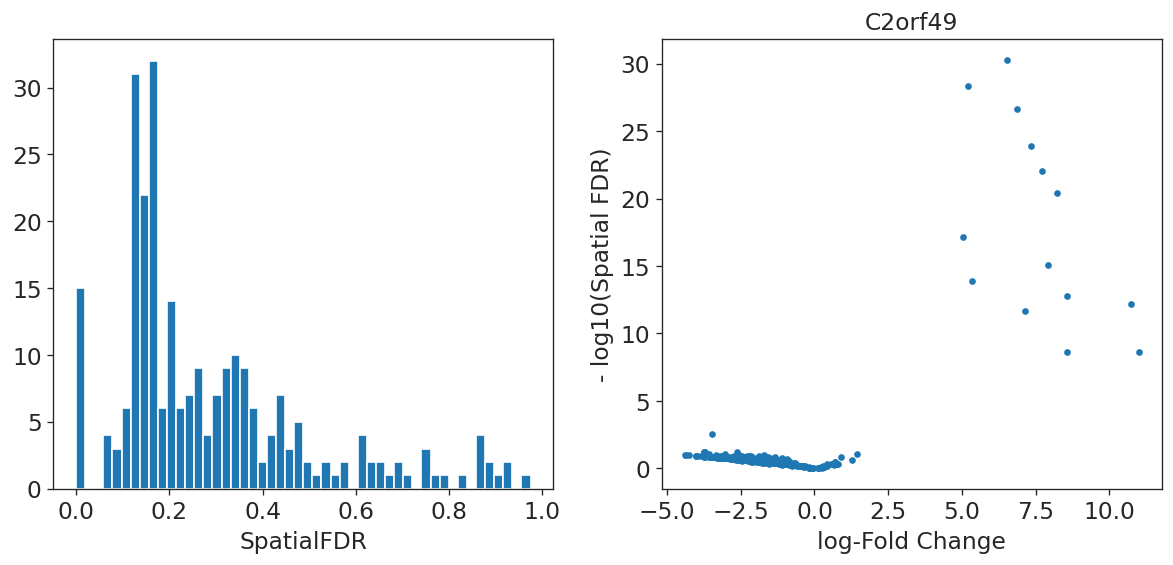

In [10]:
milo_res = run_milo(cd_iN, 'C2orf49',
                    pert_colname='perturbation',
                    rep_colname='Replicate',
                   use_rep='CellDISECT_Z_not_Replicate')   

In [16]:
cd_iN[cd_iN.obs.perturbation.isin(['INT','C2orf49'])].obs.perturbation.value_counts()

perturbation
INT        6486
C2orf49     367
Name: count, dtype: int64

/software/cellgen/team233/so21/envs/scanpy/lib/python3.12/site-packages/scanpy/plotting/_utils.py:465: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  adata.uns[f"{value_to_plot}_colors"] = colors_list


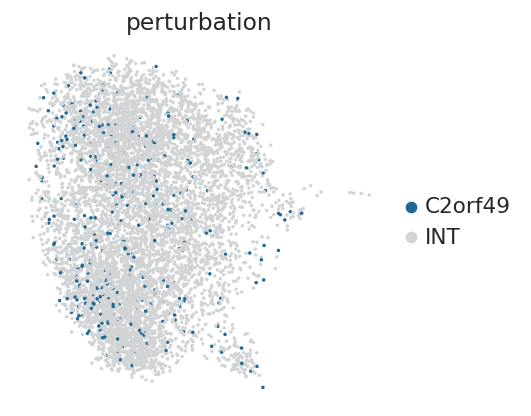

In [15]:
sc.pl.umap(cd_iN[cd_iN.obs.perturbation.isin(['INT','C2orf49'])], color='perturbation', palette = ['#216893','#d1d3d4'],
          frameon=False,
          save='_iN_pool_C2orf49only.pdf')

/software/cellgen/team233/so21/envs/scanpy/lib/python3.12/site-packages/scanpy/plotting/_utils.py:465: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  adata.uns[f"{value_to_plot}_colors"] = colors_list


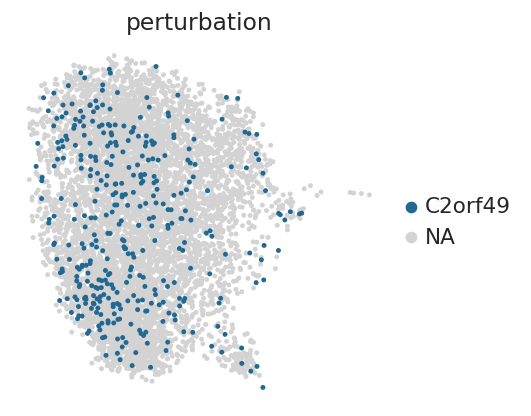

In [19]:
sc.pl.umap(cd_iN[cd_iN.obs.perturbation.isin(['INT','C2orf49'])], color='perturbation', palette = ['#216893','#d1d3d4'],
          frameon=False,
           size =35,groups='C2orf49',
          save='_iN_pool_C2orf49only2.pdf')

/software/cellgen/team233/so21/envs/scanpy/lib/python3.12/site-packages/scanpy/plotting/_utils.py:465: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  adata.uns[f"{value_to_plot}_colors"] = colors_list


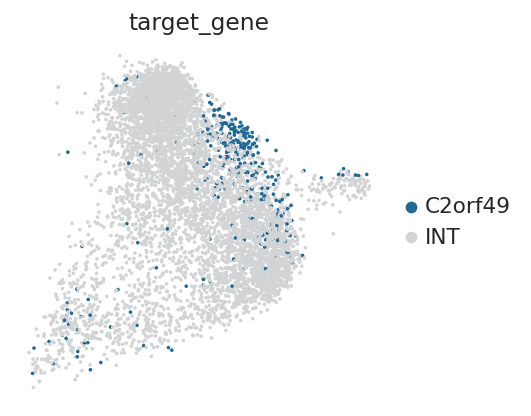

In [26]:
sc.pl.umap(cd_iN[cd_iN.obs.target_gene.isin(['INT','C2orf49'])], color='target_gene', palette = ['#216893','#d1d3d4'],
          frameon=False,
          save='_iN_pool_C2orf49only.pdf')

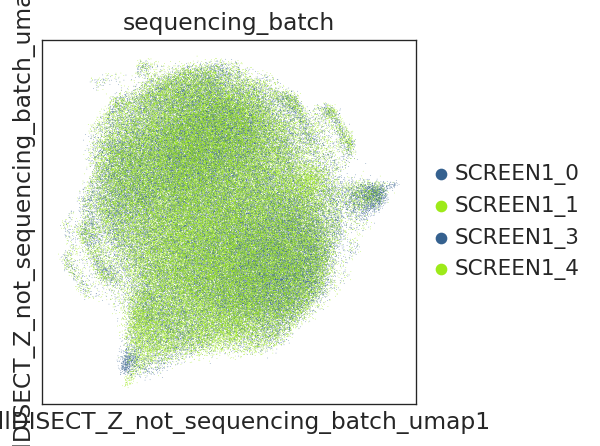

In [27]:
sc.pl.embedding(cd_iN, 'CellDISECT_Z_not_sequencing_batch_umap', color='sequencing_batch', palette=["#35618f", "#9dea19",],
               )

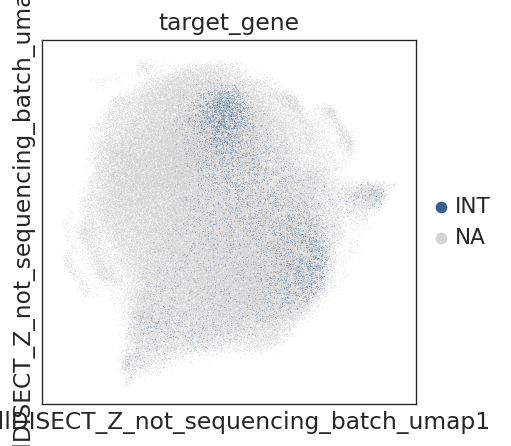

In [28]:
sc.pl.embedding(cd_iN, 'CellDISECT_Z_not_sequencing_batch_umap', color='target_gene',groups='INT', palette=["#35618f", "#9dea19",],
               )

/software/cellgen/team233/so21/envs/scanpy/lib/python3.12/site-packages/scanpy/plotting/_utils.py:465: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  adata.uns[f"{value_to_plot}_colors"] = colors_list


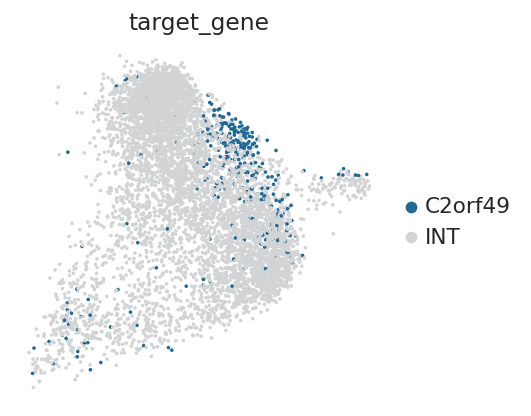

In [30]:
sc.pl.umap(cd_iN[cd_iN.obs.target_gene.isin(['INT','C2orf49'])], color='target_gene', palette = ['#216893','#d1d3d4'],
          frameon=False,
          save='_iN_pool_C2orf49only.pdf')